<a href="https://colab.research.google.com/github/Alvarojm13/tfm-cleveland/blob/main/01_datos_y_eda2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TFM · Notebook 01 — Datos, calidad y análisis exploratorio

**Objetivo de este notebook (Fases 2 y 3 del plan):**

1. Cargar los datos originales de UCI (`processed.cleveland.data`).
2. Comprobar la calidad: valores perdidos, duplicados y rangos.
3. Documentar que el `heart.csv` del máster tenía 6 valores imputados.
4. Crear la variable respuesta binaria y recodificar `restecg`.
5. Construir la **Tabla 1** (descriptiva por desenlace) y las figuras del EDA.
6. Guardar un fichero limpio para el notebook 02.

**Regla de oro:** este notebook *describe*; no elige variables ni toca el modelo.
Aquí todavía **no** se imputa nada: la imputación se hará dentro del `Pipeline`
en el notebook 02, ajustada solo con el 80 % de entrenamiento.

**Cómo usarlo en Google Colab:** `Entorno de ejecución → Ejecutar todas`.
Cuando lo pida, sube `processed.cleveland.data` (y, si quieres la comprobación del paso 3, también `heart.csv`).

## 1. Librerías

In [ ]:
# pandas: tablas de datos | numpy: cálculos | scipy: pruebas estadísticas | matplotlib: gráficos
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
SEMILLA = 42                       # misma semilla en todo el TFM (reproducibilidad)
os.makedirs("figures", exist_ok=True)  # carpeta para guardar las figuras de la memoria

## 2. Carga de los datos originales

In [ ]:
import os
import pandas as pd

# En Colab aparece un botón para subir archivos. Fuera de Colab, deja los ficheros
# en la misma carpeta que el notebook y no se pedirá nada.
try:
    from google.colab import files
    if not os.path.exists("processed.cleveland.data"):
        print("Sube processed.cleveland.data (y opcionalmente heart.csv):")
        files.upload()
except ImportError:
    pass  # no estamos en Colab

COLUMNAS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# El fichero no tiene cabecera y marca los perdidos con "?"
df = pd.read_csv("processed.cleveland.data", header=None,
                 names=COLUMNAS, na_values="?")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Diccionario de variables

| Variable | Significado | Tipo | Unidad / códigos |
|---|---|---|---|
| age | Edad | Continua | años |
| sex | Sexo | Binaria | 0 = mujer, 1 = hombre |
| cp | Tipo de dolor torácico | Nominal | 1 = angina típica, 2 = atípica, 3 = no anginoso, 4 = asintomático |
| trestbps | PA sistólica en reposo | Continua | mmHg |
| chol | Colesterol sérico | Continua | mg/dl |
| fbs | Glucemia en ayunas > 120 mg/dl | Binaria | 0 = no, 1 = sí |
| restecg | ECG en reposo | Nominal | 0 = normal, 1 = anomalía ST-T, 2 = HVI |
| thalach | FC máxima alcanzada | Continua | lpm |
| exang | Angina inducida por ejercicio | Binaria | 0 = no, 1 = sí |
| oldpeak | Descenso del ST con el ejercicio | Continua | mm |
| slope | Pendiente del ST en el pico | Nominal | 1 = ascendente, 2 = plana, 3 = descendente |
| ca | Vasos principales coloreados por fluoroscopia | Discreta | 0–3 |
| thal | Gammagrafía con talio | Nominal | 3 = normal, 6 = defecto fijo, 7 = defecto reversible |
| num | Diagnóstico angiográfico | Ordinal | 0 = < 50 % de estenosis; 1–4 = > 50 % |

Fuente: ficha del dataset en UCI (Janosi et al., 1989) y fichero `heart-disease.names`.

## 3. Calidad de los datos

In [ ]:
print("Valores perdidos por variable:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nFilas con algún perdido:", df.isna().any(axis=1).sum())
print("Filas duplicadas:", df.duplicated().sum())
df[df.isna().any(axis=1)]

Valores perdidos por variable:
ca      4
thal    2
dtype: int64

Filas con algún perdido: 6
Filas duplicadas: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [ ]:
# Rangos: mínimos y máximos para detectar valores imposibles (no solo extremos).
df.describe().T[["min", "max", "mean"]].round(1)

,min,max,mean
age,29.0,77.0,54.4
sex,0.0,1.0,0.7
cp,1.0,4.0,3.2
trestbps,94.0,200.0,131.7
chol,126.0,564.0,246.7
fbs,0.0,1.0,0.1
restecg,0.0,2.0,1.0
thalach,71.0,202.0,149.6
exang,0.0,1.0,0.3
oldpeak,0.0,6.2,1.0


### 3.1 Comprobación: el `heart.csv` del máster venía imputado

Esta celda solo se ejecuta si has subido también `heart.csv`. Compara los dos ficheros celda a celda.

In [ ]:
import numpy as np  # por si no se ejecutó la celda 1
if os.path.exists("heart.csv"):
    heart = pd.read_csv("heart.csv")
    distintas = (df.fillna(-1).values != heart.values)
    filas = np.where(distintas.any(axis=1))[0]
    print("Celdas distintas:", distintas.sum(), "| filas (índice desde 0):", filas.tolist())
    comparacion = pd.concat({"UCI original": df.loc[filas, ["ca", "thal"]],
                             "heart.csv": heart.loc[filas, ["ca", "thal"]]}, axis=1)
    display(comparacion)
else:
    print("heart.csv no está disponible: se omite la comparación.")

Celdas distintas: 6 | filas (índice desde 0): [87, 166, 192, 266, 287, 302]


UCI original      heart.csv     
              ca thal        ca thal
87           0.0  NaN       0.0  3.0
166          NaN  3.0       0.0  3.0
192          NaN  7.0       0.0  7.0
266          0.0  NaN       0.0  3.0
287          NaN  7.0       0.0  7.0
302          NaN  3.0       0.0  3.0

**Para la memoria (métodos):** el fichero proporcionado por el máster contenía 6 valores
perdidos (4 en `ca`, 2 en `thal`) ya sustituidos por la moda, antes de cualquier partición.
Se partió del fichero original de UCI y la imputación se realizó dentro del pipeline de modelado.

## 4. Variable respuesta y recodificaciones

In [ ]:
# Desenlace binario: enfermedad coronaria angiográfica (estenosis > 50 %) = num >= 1
df["enfermedad"] = (df["num"] >= 1).astype(int)
print(df["num"].value_counts().sort_index())
print("\nEventos:", df["enfermedad"].sum(), "de", len(df),
      f"({df['enfermedad'].mean():.1%})")

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Eventos: 139 de 303 (45.9%)


In [ ]:
# restecg: la categoría 1 solo tiene 4 pacientes -> normal (0) frente a anormal (1 o 2).
# Es una regla fija, no aprende de los datos, así que puede hacerse antes de la partición.
print(df["restecg"].value_counts().sort_index())
df["restecg_anormal"] = (df["restecg"] >= 1).astype(int)

restecg
0.0    151
1.0      4
2.0    148
Name: count, dtype: int64


## 5. Tabla 1 — características de la cohorte según el desenlace

In [ ]:
CONTINUAS = {"age": "Edad, años", "trestbps": "PA sistólica, mmHg",
             "chol": "Colesterol, mg/dl", "thalach": "FC máxima, lpm",
             "oldpeak": "Descenso ST, mm"}
CATEGORICAS = {
    "sex": ("Sexo", {0: "Mujer", 1: "Hombre"}),
    "cp": ("Tipo de dolor", {1: "Angina típica", 2: "Angina atípica",
                             3: "Dolor no anginoso", 4: "Asintomático"}),
    "fbs": ("Glucemia > 120 mg/dl", {0: "No", 1: "Sí"}),
    "restecg_anormal": ("ECG en reposo", {0: "Normal", 1: "Anormal"}),
    "exang": ("Angina con el ejercicio", {0: "No", 1: "Sí"}),
    "slope": ("Pendiente del ST", {1: "Ascendente", 2: "Plana", 3: "Descendente"}),
    "ca": ("Vasos coloreados", {0: "0", 1: "1", 2: "2", 3: "3"}),
    "thal": ("Talio", {3: "Normal", 6: "Defecto fijo", 7: "Defecto reversible"}),
}

def tabla_1(datos, grupo, etiquetas_grupo):
    # Continuas: media ± DE si son aproximadamente normales (Shapiro p > 0,05 en ambos grupos),
    # si no, mediana [RIC]. Categóricas: n (%), con % por columna. Se informan los perdidos.
    g0, g1 = [datos[datos[grupo] == k] for k in (0, 1)]
    filas = []
    for var, nombre in CONTINUAS.items():
        a, b, tot = g0[var].dropna(), g1[var].dropna(), datos[var].dropna()
        normal = stats.shapiro(a).pvalue > 0.05 and stats.shapiro(b).pvalue > 0.05
        if normal:
            f = lambda x: f"{x.mean():.1f} ± {x.std():.1f}"
            p = stats.ttest_ind(a, b, equal_var=False).pvalue
        else:
            f = lambda x: f"{x.median():.1f} [{x.quantile(.25):.1f}–{x.quantile(.75):.1f}]"
            p = stats.mannwhitneyu(a, b).pvalue
        filas.append([nombre, f(tot), f(a), f(b), p])
    for var, (nombre, codigos) in CATEGORICAS.items():
        tabla = pd.crosstab(datos[var], datos[grupo])
        p = stats.chi2_contingency(tabla).pvalue if tabla.shape[0] > 1 else np.nan
        filas.append([nombre, "", "", "", p])
        for cod, txt in codigos.items():
            n_tot = (datos[var] == cod).sum()
            n0, n1 = (g0[var] == cod).sum(), (g1[var] == cod).sum()
            filas.append([f"   {txt}", f"{n_tot} ({n_tot/datos[var].notna().sum():.0%})",
                          f"{n0} ({n0/g0[var].notna().sum():.0%})",
                          f"{n1} ({n1/g1[var].notna().sum():.0%})", np.nan])
        if datos[var].isna().any():
            filas.append(["   Perdidos", str(datos[var].isna().sum()),
                          str(g0[var].isna().sum()), str(g1[var].isna().sum()), np.nan])
    cab = ["Variable", f"Total (n = {len(datos)})",
           f"{etiquetas_grupo[0]} (n = {len(g0)})", f"{etiquetas_grupo[1]} (n = {len(g1)})", "p"]
    t = pd.DataFrame(filas, columns=cab)
    t["p"] = t["p"].apply(lambda x: "" if pd.isna(x) else ("< 0.001" if x < 0.001 else f"{x:.3f}"))
    # Coma decimal, como corresponde a un texto en español
    for col in t.columns[1:]:
        t[col] = t[col].str.replace(".", ",", regex=False)
    return t

t1 = tabla_1(df, "enfermedad", ("Sin enfermedad", "Con enfermedad"))
t1.to_csv("figures/tabla1_por_desenlace.csv", index=False)
t1

,Variable,Total (n = 303),Sin enfermedad (n = 164),Con enfermedad (n = 139),p
0,"Edad, años","56,0 [48,0–61,0]","52,0 [44,8–59,0]","58,0 [52,0–62,0]","< 0,001"
1,"PA sistólica, mmHg","130,0 [120,0–140,0]","130,0 [120,0–140,0]","130,0 [120,0–145,0]","0,026"
2,"Colesterol, mg/dl","241,0 [211,0–275,0]","234,5 [208,8–267,2]","249,0 [217,5–283,5]","0,035"
3,"FC máxima, lpm","153,0 [133,5–166,0]","161,0 [148,8–172,0]","142,0 [125,0–156,5]","< 0,001"
4,"Descenso ST, mm","0,8 [0,0–1,6]","0,2 [0,0–1,0]","1,4 [0,6–2,5]","< 0,001"
5,Sexo,,,,"< 0,001"
6,Mujer,97 (32%),72 (44%),25 (18%),
7,Hombre,206 (68%),92 (56%),114 (82%),
8,Tipo de dolor,,,,"< 0,001"
9,Angina típica,23 (8%),16 (10%),7 (5%),


**Cómo leerla:** las p-valores solo *describen* diferencias entre grupos; **no** se usan
para elegir variables (eso sería fuga de información). Pruebas usadas: t de Welch o
U de Mann-Whitney para continuas y χ² para categóricas. Con celdas pequeñas (`restecg`,
`slope` descendente), el χ² es aproximado: decláralo como limitación.

### 5.1 Tabla 1 por sexo (anexo)

In [ ]:
t1_sexo = tabla_1(df.rename(columns={"sex": "sexo"}).assign(sex=df["sex"]),
                  "sexo", ("Mujeres", "Hombres"))
t1_sexo = t1_sexo[~t1_sexo["Variable"].str.strip().isin(["Sexo", "Mujer", "Hombre"])]
t1_sexo.to_csv("figures/tabla1_por_sexo.csv", index=False)
t1_sexo

,Variable,Total (n = 303),Mujeres (n = 97),Hombres (n = 206),p
0,"Edad, años","56,0 [48,0–61,0]","57,0 [50,0–63,0]","54,5 [47,0–59,8]","0,084"
1,"PA sistólica, mmHg","130,0 [120,0–140,0]","132,0 [120,0–140,0]","130,0 [120,0–140,0]","0,290"
2,"Colesterol, mg/dl","241,0 [211,0–275,0]","254,0 [215,0–302,0]","235,0 [208,8–268,5]","0,007"
3,"FC máxima, lpm","153,0 [133,5–166,0]","157,0 [142,0–165,0]","150,5 [132,0–167,5]","0,429"
4,"Descenso ST, mm","0,8 [0,0–1,6]","0,6 [0,0–1,4]","0,8 [0,0–1,8]","0,059"
8,Tipo de dolor,,,,"0,079"
9,Angina típica,23 (8%),4 (4%),19 (9%),
10,Angina atípica,50 (17%),18 (19%),32 (16%),
11,Dolor no anginoso,86 (28%),35 (36%),51 (25%),
12,Asintomático,144 (48%),40 (41%),104 (50%),


## 6. El hallazgo del tipo de dolor torácico

In [ ]:
# Prevalencia de enfermedad por tipo de dolor: en Diamond y Forrester (1979) la angina típica
# tiene la mayor probabilidad. Aquí ocurre lo contrario: es un resultado a discutir.
dolor = df.groupby("cp")["enfermedad"].agg(n="count", con_enfermedad="sum", prevalencia="mean")
dolor.index = dolor.index.map(CATEGORICAS["cp"][1])
dolor["prevalencia"] = (dolor["prevalencia"] * 100).round(1)
dolor

,n,con_enfermedad,prevalencia
cp,,,
Angina típica,23,7,30.4
Angina atípica,50,9,18.0
Dolor no anginoso,86,18,20.9
Asintomático,144,105,72.9


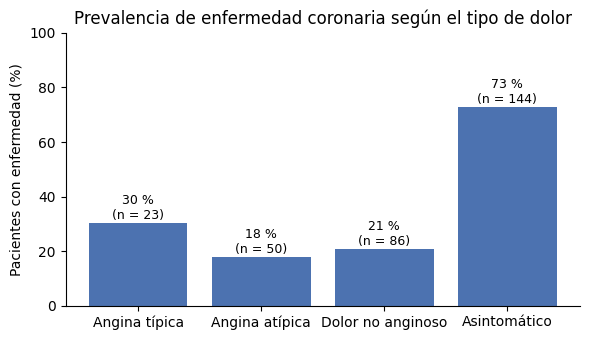

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dolor.index, dolor["prevalencia"], color="#4C72B0")
for i, (v, n) in enumerate(zip(dolor["prevalencia"], dolor["n"])):
    ax.text(i, v + 1.5, f"{v:.0f} %\n(n = {n})", ha="center", fontsize=9)
ax.set_ylabel("Pacientes con enfermedad (%)")
ax.set_ylim(0, 100)
ax.set_title("Prevalencia de enfermedad coronaria según el tipo de dolor")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig_prevalencia_por_dolor.png", dpi=300)
plt.show()

## 7. Distribución de las variables continuas según el desenlace

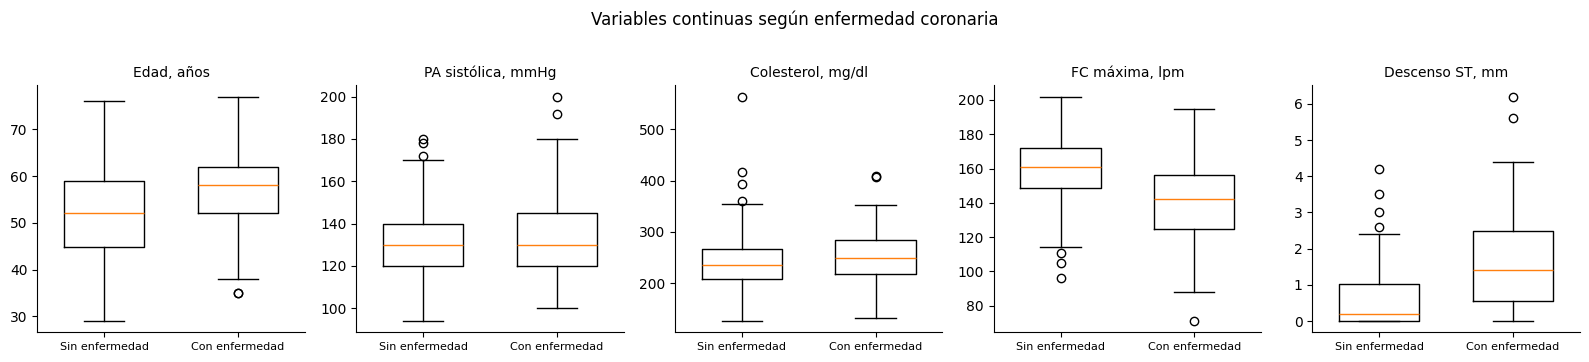

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, (var, nombre) in zip(axes, CONTINUAS.items()):
    datos = [df.loc[df["enfermedad"] == k, var].dropna() for k in (0, 1)]
    ax.boxplot(datos, widths=0.6)
    ax.set_xticks([1, 2], ["Sin enfermedad", "Con enfermedad"], fontsize=8)
    ax.set_title(nombre, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Variables continuas según enfermedad coronaria", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig_continuas_por_desenlace.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Correlación entre variables continuas (Spearman)

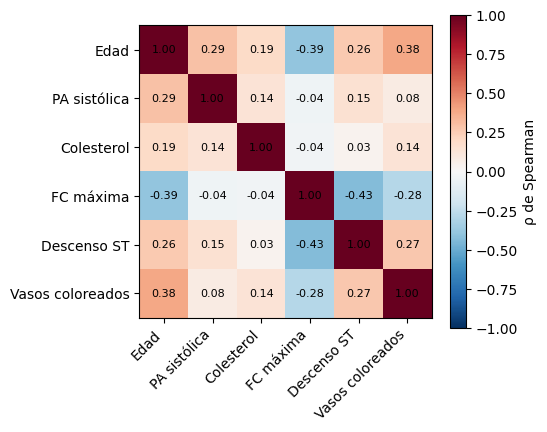

In [ ]:
# Sirve para detectar redundancias (colinealidad), no para seleccionar variables.
corr = df[list(CONTINUAS) + ["ca"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
etiquetas = [CONTINUAS.get(c, "Vasos coloreados").split(",")[0] for c in corr.columns]
ax.set_xticks(range(len(corr)), etiquetas, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), etiquetas)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="ρ de Spearman")
plt.tight_layout()
plt.savefig("figures/fig_correlacion_spearman.png", dpi=300)
plt.show()

## 9. Guardar los datos para el notebook 02

In [ ]:
# Se guardan CON los perdidos: la imputación se hará en el notebook 02, dentro del Pipeline.
df.to_csv("datos_cleveland_limpios.csv", index=False)
print("Guardado datos_cleveland_limpios.csv:", df.shape)
try:
    from google.colab import files
    files.download("datos_cleveland_limpios.csv")
except ImportError:
    pass

Guardado datos_cleveland_limpios.csv: (303, 16)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# La carpeta figures/ se borra al cerrar la sesión de Colab: se comprime y se descarga.
import os, shutil
shutil.make_archive("figuras_tfm", "zip", "figures")
print("Contenido de figuras_tfm.zip:", sorted(os.listdir("figures")))
from google.colab import files
files.download("figuras_tfm.zip")

Contenido de figuras_tfm.zip: ['fig_continuas_por_desenlace.png', 'fig_correlacion_spearman.png', 'fig_prevalencia_por_dolor.png', 'tabla1_por_desenlace.csv', 'tabla1_por_sexo.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Qué llevar a la memoria

- **Métodos:** fuente de datos (UCI, Cleveland Clinic), 303 pacientes, definición del desenlace
  (`num` ≥ 1), los 6 perdidos y su origen, la recodificación de `restecg`, y las pruebas
  estadísticas de la Tabla 1.
- **Resultados:** Tabla 1 (por desenlace), figura de prevalencia por tipo de dolor y figura
  de variables continuas. La Tabla 1 por sexo y la matriz de correlación, a anexos.
- **Discusión:** la relación inversa entre tipo de dolor y enfermedad, y por qué anticipa
  el mal rendimiento de la tabla de Diamond y Forrester en esta población remitida.